<a href="https://colab.research.google.com/github/aishasheikh009900/ML-projects/blob/main/house_pred.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/content/Housing.csv")
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [3]:
df.columns


Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

In [4]:
df.dtypes

,0
price,int64
area,int64
bedrooms,int64
bathrooms,int64
stories,int64
mainroad,object
guestroom,object
basement,object
hotwaterheating,object
airconditioning,object


In [5]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [7]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [8]:
df.duplicated().sum()

np.int64(0)

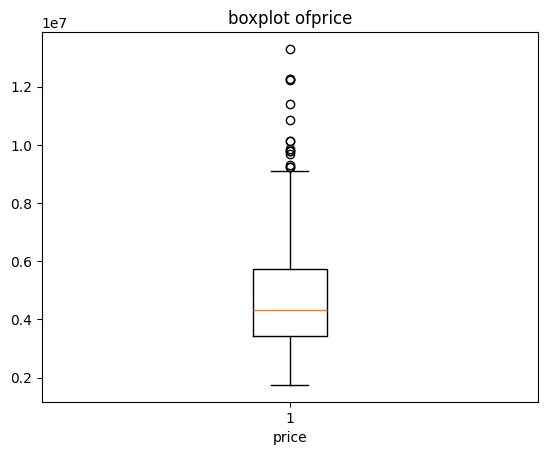

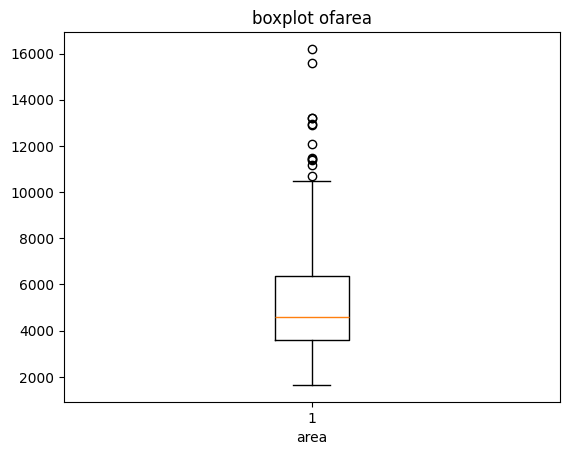

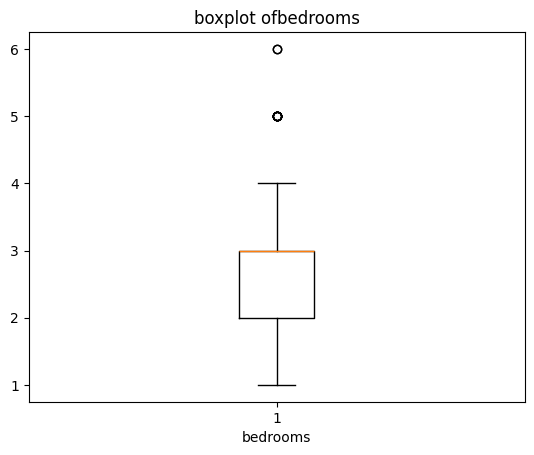

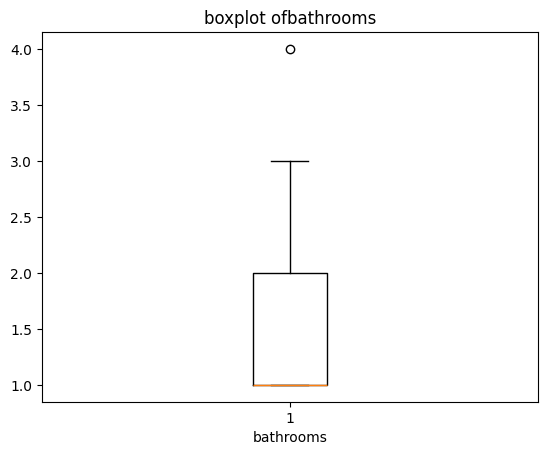

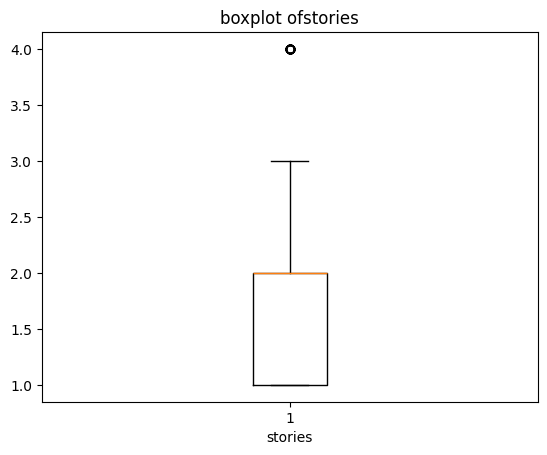

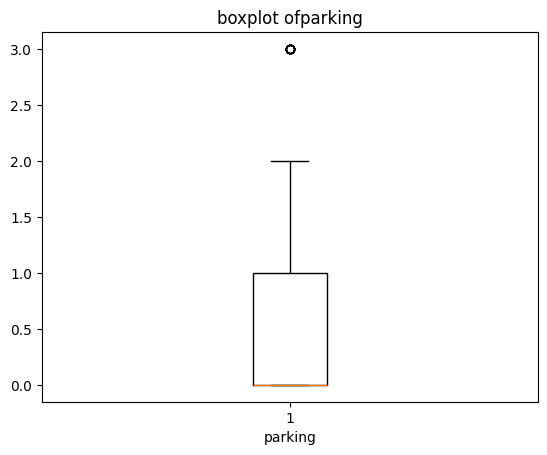

In [9]:
numeric_col = df.select_dtypes(include="number").columns

for col in numeric_col:
  plt.figure()
  plt.boxplot(df[col])
  plt.title(f'boxplot of{col}')
  plt.xlabel(col)
  plt.show()

In [10]:
for col in numeric_col:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  df[col] = df[col].clip(lower_bound, upper_bound)

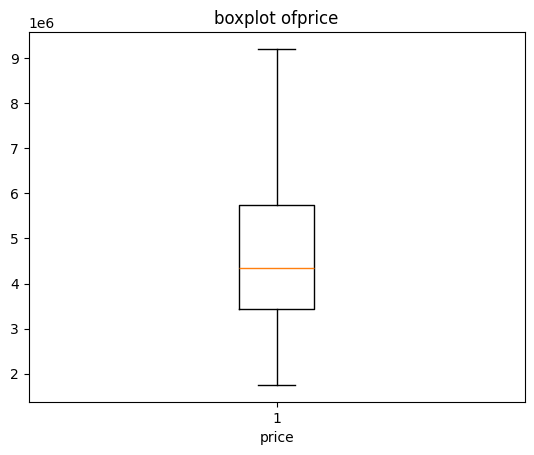

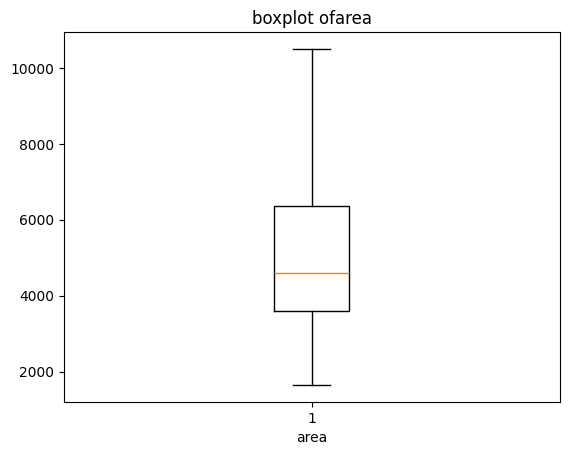

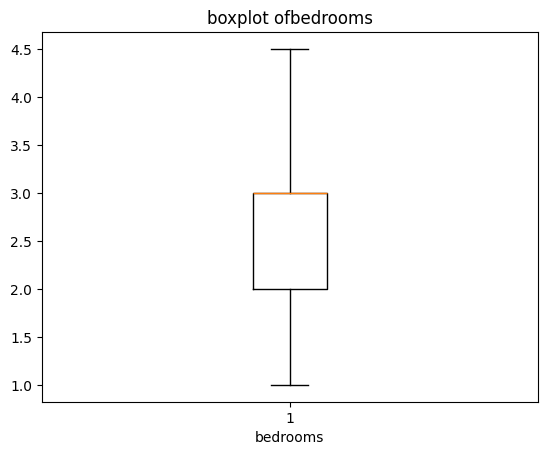

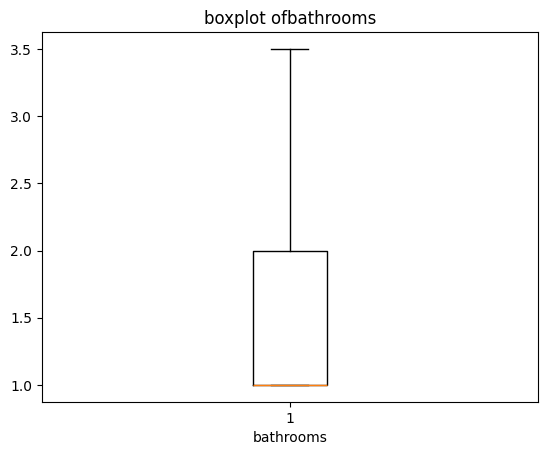

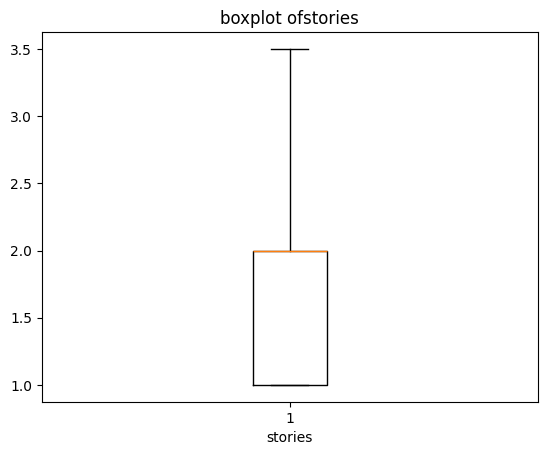

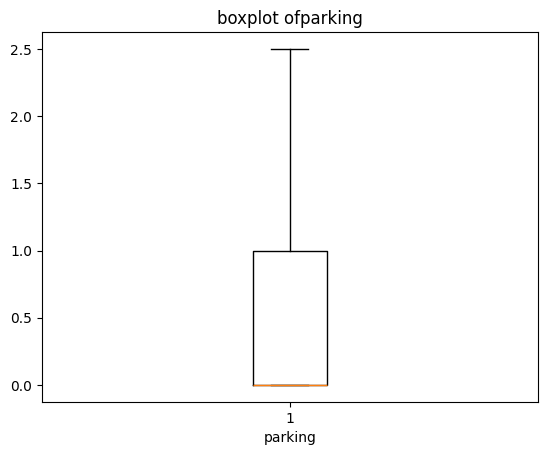

In [11]:
numeric_col = df.select_dtypes(include="number").columns

for col in numeric_col:
  plt.figure()
  plt.boxplot(df[col])
  plt.title(f'boxplot of{col}')
  plt.xlabel(col)
  plt.show()

In [13]:
import pandas as pd

# 1. Ordinal aur Nominal columns ki list
ordinal_cols = ['furnishingstatus']
nominal_cols = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea',
]

# 2. Ordinal column ('furnishingstatus') ko sahi order mein numbers (0, 1, 2) dena
if 'furnishingstatus' in df.columns and df['furnishingstatus'].dtype == 'object':
  df['furnishingstatus'] = df['furnishingstatus'].map(
      {'unfurnished': 0, 'semi-furnished': 1, 'furnished': 2}
  )

# 3. Nominal columns par One-Hot Encoding (get_dummies)
existing_nominal = [col for col in nominal_cols if col in df.columns]
if existing_nominal:
  df = pd.get_dummies(df, columns=existing_nominal, drop_first=True)

# 4. Check karne ke liye
df.head()

,price,area,bedrooms,bathrooms,stories,parking,furnishingstatus,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes
0,9205000,7420,4.0,2.0,3.0,2.0,2,True,False,False,False,True,True
1,9205000,8960,4.0,3.5,3.5,2.5,2,True,False,False,False,True,False
2,9205000,9960,3.0,2.0,2.0,2.0,1,True,False,True,False,False,True
3,9205000,7500,4.0,2.0,2.0,2.5,2,True,False,True,False,True,True
4,9205000,7420,4.0,1.0,2.0,2.0,2,True,True,True,False,True,False


In [15]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in ordinal_cols:
  df[col] = le.fit_transform(df[col])

In [18]:
# Filter out columns that have already been encoded or don't exist in df
existing_nominal = [col for col in nominal_cols if col in df.columns]
if existing_nominal:
    df = pd.get_dummies(df, columns=existing_nominal, drop_first=True)

df.head()

,price,area,bedrooms,bathrooms,stories,parking,furnishingstatus,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes
0,9205000,7420,4.0,2.0,3.0,2.0,2,True,False,False,False,True,True
1,9205000,8960,4.0,3.5,3.5,2.5,2,True,False,False,False,True,False
2,9205000,9960,3.0,2.0,2.0,2.0,1,True,False,True,False,False,True
3,9205000,7500,4.0,2.0,2.0,2.5,2,True,False,True,False,True,True
4,9205000,7420,4.0,1.0,2.0,2.0,2,True,True,True,False,True,False


In [20]:
from sklearn.model_selection import train_test_split

X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [23]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [24]:
y_pred=model.predict(X_test_scaled)

In [26]:
from sklearn.metrics import r2_score, mean_absolute_error

print("R-squared:", r2_score(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))

R-squared: 0.6766374954615078
Mean Absolute Error: 892277.2562874869
